In [163]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [164]:
data_train = pd.read_csv('./Titanic_train.csv')
data_test = pd.read_csv('./titanic_test.csv')
raw_test_data = pd.read_csv('./titanic_test.csv')

In [165]:
data_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [166]:
data_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [167]:
data_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [168]:
data_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


<Axes: >

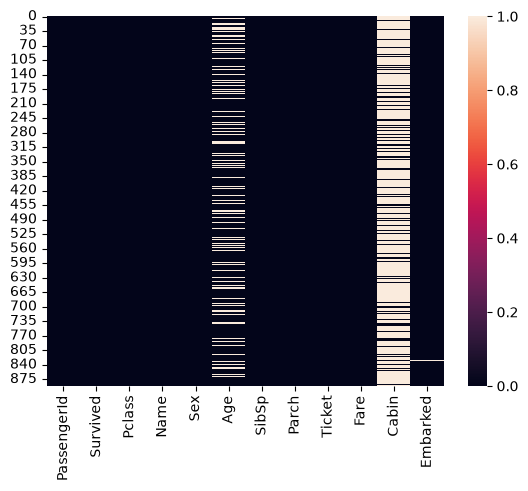

In [169]:
sns.heatmap(data_train.isnull())

<Axes: >

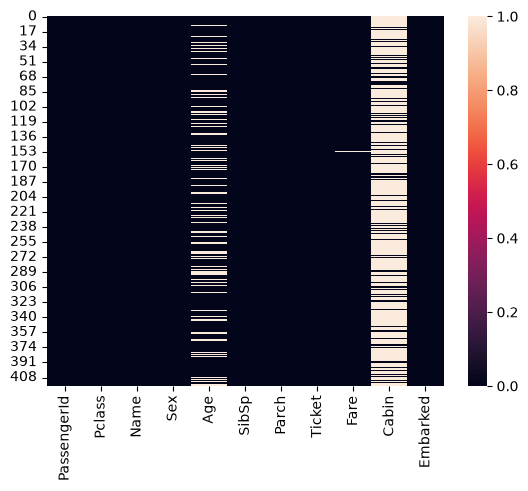

In [170]:
sns.heatmap(data_test.isnull())

In [171]:
data_train.drop(columns=['Cabin'], inplace=True)
data_test.drop(columns=['Cabin'], inplace=True)


In [172]:
data_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [173]:
pclass_1_mean = data_train[data_train['Pclass']== 1]['Age'].median()
pclass_2_mean = data_train[data_train['Pclass']== 2]['Age'].median()
pclass_3_mean = data_train[data_train['Pclass']== 3]['Age'].median()

In [174]:
pclass_1_mean_t = data_test[data_test['Pclass']== 1]['Age'].median()
pclass_2_mean_t= data_test[data_test['Pclass']== 2]['Age'].median()
pclass_3_mean_t= data_test[data_test['Pclass']== 3]['Age'].median()

In [175]:
def fill_age(columns):
    Age = columns['Age']
    Pclass = columns['Pclass']
    if pd.isnull(Age):
        if Pclass == 1:
            return pclass_1_mean
        elif Pclass == 2:
            return pclass_2_mean
        else:
            return pclass_3_mean
    else:
        return Age

In [176]:
data_train['Age'] = data_train[['Age','Pclass']].apply(fill_age,axis=1)

In [177]:
def fill_age(columns):
    Age = columns['Age']
    Pclass = columns['Pclass']
    if pd.isnull(Age):
        if Pclass == 1:
            return pclass_1_mean_t
        elif Pclass == 2:
            return pclass_2_mean_t
        else:
            return pclass_3_mean_t
    else:
        return Age

In [178]:
data_test['Age'] = data_test[['Age','Pclass']].apply(fill_age,axis=1)

In [179]:
data_train.dropna(inplace=True)


In [180]:
# Train data-r median fare use kora safe, jate data leakage na hoy
fare_median = data_train.groupby('Pclass')['Fare'].median()

# Test dataset-e Pclass onushare Fare fill kora
data_test['Fare'] = data_test['Fare'].fillna(data_test['Pclass'].map(fare_median))

In [181]:
data_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          418 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         418 non-null    float64
 9   Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(4)
memory usage: 32.8 KB


In [182]:
data_train.drop(
    columns=['PassengerId','Ticket'], 
    inplace=True
)

data_test.drop(
    columns=['PassengerId','Ticket'], 
    inplace=True
)

In [183]:
data_train = pd.get_dummies(
    data=data_train,
    columns=['Sex','Embarked','Name'],
    drop_first=True
)
data_test = pd.get_dummies(
    data=data_test,
    columns=['Sex','Embarked','Name'],
    drop_first=True
)

In [184]:
data_train

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,"Name_Abbott, Mr. Rossmore Edward",...,"Name_Yrois, Miss. Henriette (""Mrs Harbeck"")","Name_Zabour, Miss. Hileni","Name_Zabour, Miss. Thamine","Name_Zimmerman, Mr. Leo","Name_de Messemaeker, Mrs. Guillaume Joseph (Emma)","Name_de Mulder, Mr. Theodore","Name_de Pelsmaeker, Mr. Alfons","Name_del Carlo, Mr. Sebastiano","Name_van Billiard, Mr. Austin Blyler","Name_van Melkebeke, Mr. Philemon"
0,0,3,22.0,1,0,7.2500,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
1,1,1,38.0,1,0,71.2833,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
3,1,1,35.0,1,0,53.1000,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
4,0,3,35.0,0,0,8.0500,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
887,1,1,19.0,0,0,30.0000,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
888,0,3,24.0,1,2,23.4500,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
889,1,1,26.0,0,0,30.0000,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [185]:
target = data_train['Survived']
feature = data_train.drop(columns='Survived')

In [186]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)

In [187]:
model.fit(feature,target)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [188]:
prediction = model.predict(data_test)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- Name_Abelseth, Miss. Karen Marie
- Name_Abelseth, Mr. Olaus Jorgensen
- Name_Abrahamsson, Mr. Abraham August Johannes
- Name_Abrahim, Mrs. Joseph (Sophie Halaut Easu)
- Name_Aks, Master. Philip Frank
- ...
Feature names seen at fit time, yet now missing:
- Name_Abbott, Mr. Rossmore Edward
- Name_Abbott, Mrs. Stanton (Rosa Hunt)
- Name_Abelson, Mr. Samuel
- Name_Abelson, Mrs. Samuel (Hannah Wizosky)
- Name_Adahl, Mr. Mauritz Nils Martin
- ...


In [ ]:


submission = pd.DataFrame({
    'PassengerId': raw_test_data['PassengerId'], 
    'Survived': prediction
})

submission.to_csv('submission.csv', index=False)